# 5. Simulating portfolio losses: would bank capital have covered 2009?

Notebooks 2–4 describe *individual* loans. A bank needs the distribution of losses of the **whole portfolio**, because defaults are not independent: when the economy turns, many borrowers default together. Regulatory capital for mortgages (Basel IRB) comes from a one-factor model of that dependence. This notebook:

1. calibrates the model on the **2017** book (a normal period);
2. simulates its loss distribution by Monte Carlo and checks it against the closed-form Basel formula;
3. uses **importance sampling** to estimate tail probabilities precisely;
4. asks how extreme the **2006 vintage's crisis years** were under that model.

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.stats import norm

from credit_risk.data import load_loans

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREY = "#1a73e8", "#d93025", "#80868b"
rng = np.random.default_rng(2026)

loans = load_loans((2006, 2017)).dropna(subset=["fico"])
loans["band"] = pd.cut(loans["fico"], [300, 660, 720, 760, 851], right=False,
                       labels=["< 660", "660–719", "720–759", "760+"])

## The model

Each loan *i* defaults within a year if a latent variable falls below a threshold:

$$ X_i = \sqrt{\rho}\, Z + \sqrt{1-\rho}\, \varepsilon_i, \qquad \text{default if } X_i < \Phi^{-1}(PD_i), $$

where $Z \sim N(0,1)$ is the **economy**, shared by all loans, and $\varepsilon_i$ is the borrower's own luck. Given the economy, defaults are independent with probability

$$ p_i(Z) = \Phi\!\left(\frac{\Phi^{-1}(PD_i) - \sqrt{\rho}\, Z}{\sqrt{1-\rho}}\right). $$

A bad year is a low $Z$. The correlation $\rho$ measures how much the economy drives defaults; Basel fixes $\rho = 0.15$ for residential mortgages.

## Calibration on the 2017 book

One-year probability of default by credit-score band, estimated as defaults per loan-year of exposure (the same "events over time observed" estimator used in the pedestrian-crash project), and exposure at default as the original balance:

In [2]:
book = loans[loans["vintage"] == 2017]
calib = book.groupby("band", observed=True).agg(loans=("loan_id", "size"), ead=("upb", "sum"),
                                                defaults=("event", lambda s: (s == 1).sum()),
                                                loan_years=("time", lambda s: s.sum() / 12))
calib["pd_1y"] = 1 - np.exp(-calib["defaults"] / calib["loan_years"])
calib["ead_per_loan"] = calib["ead"] / calib["loans"]

# Loss given default: the 2006 crisis value per defaulted dollar (notebook 1), as Basel asks for a
# "downturn" LGD. Normal-times LGD in 2017 was below 1%, which would make capital meaningless.
d06 = loans[(loans["vintage"] == 2006) & (loans["event"] == 1)]
LGD = d06["actual_loss"].where(d06["zbc"].isin(["02", "03", "09"]), 0).fillna(0).sum() / d06["upb_default"].sum()
RHO = 0.15
calib[["loans", "pd_1y", "ead_per_loan"]].assign(LGD=LGD)

,loans,pd_1y,ead_per_loan,LGD
band,,,,
< 660,2537,0.0192,193152.5424,0.2657
660–719,12384,0.0096,225439.8417,0.2657
720–759,12794,0.0046,237048.1476,0.2657
760+,22277,0.0021,232908.6951,0.2657


## Monte Carlo of the loss distribution

For each simulated year: draw the economy $Z$, compute each band's conditional default probability, draw the number of defaults in each band (binomial, so borrower-level luck is included), and add up losses.

In [3]:
pd_b, n_b, ead_b = calib["pd_1y"].values, calib["loans"].values, calib["ead_per_loan"].values
total_ead = calib["ead"].sum()

def conditional_pd(z, pd_, rho=RHO):
    return norm.cdf((norm.ppf(pd_) - np.sqrt(rho) * z[:, None]) / np.sqrt(1 - rho))

def simulate_losses(z, rho=RHO):
    p = conditional_pd(z, pd_b, rho)
    defaults = rng.binomial(n_b, p)
    return (defaults * ead_b * LGD).sum(axis=1) / total_ead     # loss as a share of the book

N = 200_000
z = rng.standard_normal(N)
loss = simulate_losses(z)

el = loss.mean()
var999 = np.quantile(loss, 0.999)
es999 = loss[loss >= var999].mean()

# Closed form (Basel / Vasicek asymptotic portfolio): loss at the 99.9% quantile of the economy
asym = (ead_b * n_b * LGD * norm.cdf((norm.ppf(pd_b) + np.sqrt(RHO) * norm.ppf(0.999)) / np.sqrt(1 - RHO))).sum() / total_ead
expected_closed = (ead_b * n_b * LGD * pd_b).sum() / total_ead

pd.DataFrame({
    "Monte Carlo": [el, var999, es999, var999 - el],
    "closed form (Basel)": [expected_closed, asym, np.nan, asym - expected_closed],
}, index=["expected loss", "99.9% loss (VaR)", "expected shortfall 99.9%", "capital = VaR − expected loss"]).map(lambda x: f"{x:.3%}" if pd.notna(x) else "")

,Monte Carlo,closed form (Basel)
expected loss,0.140%,0.141%
99.9% loss (VaR),1.708%,1.750%
expected shortfall 99.9%,2.164%,
capital = VaR − expected loss,1.567%,1.609%


Monte Carlo and the closed-form Basel formula agree closely. The formula assumes an infinitely large portfolio, and with almost 50,000 loans the borrower-level luck has averaged out. This is the kind of independent check a model validator runs: two methods, one answer.

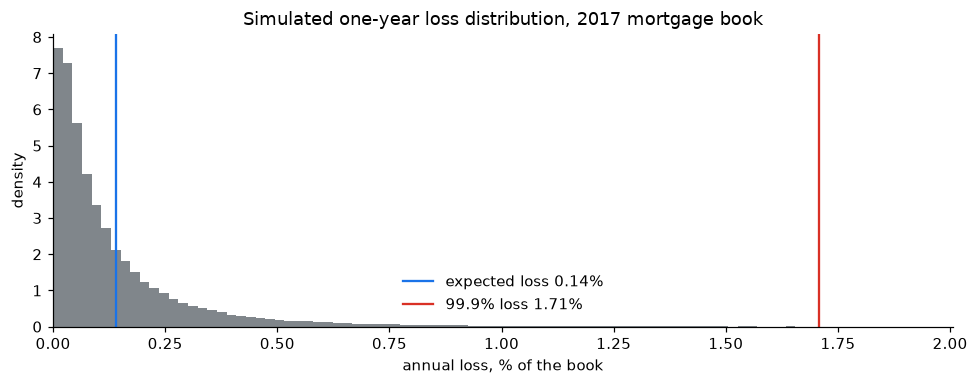

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(loss * 100, bins=200, color=GREY, density=True)
ax.axvline(el * 100, color=BLUE, label=f"expected loss {el:.2%}")
ax.axvline(var999 * 100, color=RED, label=f"99.9% loss {var999:.2%}")
ax.set_xlabel("annual loss, % of the book")
ax.set_ylabel("density")
ax.set_xlim(0, np.quantile(loss, 0.9995) * 100)
ax.legend(frameon=False)
ax.set_title("Simulated one-year loss distribution, 2017 mortgage book")
fig.tight_layout()
fig.savefig("../figures/loss_distribution.png", bbox_inches="tight")
plt.show()

Most years lose very little; a few lose many times the average. That long right tail is why capital is set at a quantile, not at the mean.

## Importance sampling: estimating rare events precisely

The probability that losses exceed the 99.9% level is 0.001 by construction. Estimated by plain Monte Carlo with 20,000 years, only about 20 simulated years land there, so the estimate is noisy. **Importance sampling** draws the economy from a distribution shifted towards bad years, $Z \sim N(-\mu, 1)$, and corrects each draw with the likelihood ratio

$$ w(z) = \frac{\varphi(z)}{\varphi(z + \mu)} = e^{\mu z + \mu^2 / 2}. $$

In [5]:
threshold, mu, n_small, reps = asym, norm.ppf(0.999), 20_000, 200

def plain():
    return (simulate_losses(rng.standard_normal(n_small)) > threshold).mean()

def importance():
    zz = rng.standard_normal(n_small) - mu
    w = np.exp(mu * zz + mu**2 / 2)
    return ((simulate_losses(zz) > threshold) * w).mean()

est_plain = np.array([plain() for _ in range(reps)])
est_is = np.array([importance() for _ in range(reps)])
pd.DataFrame({
    "mean estimate": [est_plain.mean(), est_is.mean()],
    "standard error (sd over 200 runs)": [est_plain.std(), est_is.std()],
    "relative error": [est_plain.std() / est_plain.mean(), est_is.std() / est_is.mean()],
}, index=["plain Monte Carlo", "importance sampling"]).assign(
    variance_reduction=lambda d: (d["standard error (sd over 200 runs)"].iloc[0] / d["standard error (sd over 200 runs)"]) ** 2)

,mean estimate,standard error (sd over 200 runs),relative error,variance_reduction
plain Monte Carlo,0.001,2.2751e-04,0.2348,1.0000
importance sampling,0.001,1.3339e-05,0.0133,290.9212


Same number of simulated years, but importance sampling gives a far more precise estimate of the tail probability: the variance-reduction factor says how many times more plain simulations would be needed for the same precision.

## How extreme was the crisis?

The 2006 vintage lived through the crisis. Its one-year default rate, calendar year by calendar year (defaults during the year over loans still at risk on January 1):

In [6]:
def yearly_default_rates(v, last_year=2025):
    g = loans[loans["vintage"] == v]
    fp = pd.to_datetime(g["first_payment_period"].astype(str), format="%Y%m").dt.to_period("M")
    rows = []
    for y in range(v + 1, last_year + 1):
        t0 = (pd.Period(f"{y}-01", "M") - fp).apply(lambda x: x.n)      # loan age on January 1
        at_risk = g["time"] > t0
        defaulted = at_risk & (g["event"] == 1) & (g["time"] <= t0 + 12)
        rows.append({"year": y, "at risk on Jan 1": int(at_risk.sum()), "defaults": int(defaulted.sum()),
                     "default rate": defaulted.sum() / at_risk.sum()})
    return pd.DataFrame(rows).set_index("year")

dr06 = yearly_default_rates(2006)
dr17 = yearly_default_rates(2017)
dr06.loc[2007:2014]

,at risk on Jan 1,defaults,default rate
year,,,
2007,48524,851,0.0175
2008,43695,927,0.0212
2009,37400,1635,0.0437
2010,26974,1189,0.0441
2011,20112,850,0.0423
2012,15644,544,0.0348
2013,10710,283,0.0264
2014,7151,169,0.0236


Under the model calibrated on the 2017 book, the portfolio default rate in a year is $\sum_b w_b\, p_b(Z)$. Solving for the economy $Z$ that produces the worst observed 2006 rate gives its quantile, i.e. how rare such a year is:

In [7]:
weights = n_b / n_b.sum()
def portfolio_dr(zv, rho=RHO):
    return (conditional_pd(np.atleast_1d(zv), pd_b, rho) * weights).sum(axis=1)

zgrid = np.linspace(-6, 3, 20001)
worst_year = dr06["default rate"].idxmax()
worst = dr06["default rate"].max()
rows = []
for rho in (0.10, 0.15, 0.25):
    drs = portfolio_dr(zgrid, rho)
    z_needed = zgrid[np.argmin(np.abs(drs - worst))]
    rows.append({"correlation rho": rho, "economy Z needed": z_needed,
                 "probability of a year at least that bad": norm.cdf(z_needed),
                 "about once every (years)": 1 / norm.cdf(z_needed),
                 "99.9% default rate": portfolio_dr(norm.ppf(0.001), rho)[0]})
tail = pd.DataFrame(rows).set_index("correlation rho")
print(f"worst observed year for the 2006 vintage: {worst_year}, default rate {worst:.2%}")
tail

worst observed year for the 2006 vintage: 2010, default rate 4.41%


,economy Z needed,probability of a year at least that bad,about once every (years),99.9% default rate
correlation rho,,,,
0.10,-3.0165,0.0013,782.1323,0.0463
0.15,-2.5764,0.0050,200.3304,0.0671
0.25,-2.1786,0.0147,68.1167,0.1147


With the Basel correlation of 0.15, the worst crisis year of the 2006 vintage corresponds to an economy seen about once every 200 years, and the 99.9% level (once in 1,000 years) sits well above it: **capital calibrated on a calm book would have covered the default rate of the worst crisis year.** The margin depends on the correlation: with 0.10 the crisis becomes a once-in-about-800-years event and the 99.9% level only just covers it; with 0.25 the margin is wide. The correlation is a regulatory parameter precisely because the answer is so sensitive to it.

(This compares default *rates*. Losses also depend on the loss given default, which in the model is already set at its crisis value.)

## Which correlation do the data imply?

The yearly default rates themselves carry information about $\rho$: if defaults were independent ($\rho = 0$), every year would have nearly the same rate. Under the model, the yearly rate $x$ of a large book with probability of default $PD$ has the Vasicek density, and $\rho$ can be estimated by maximum likelihood from both vintages' series (each with its own $PD$):

In [8]:
def vasicek_loglik(x, pd_, rho):
    a = norm.ppf(x)
    return (0.5 * np.log((1 - rho) / rho) + 0.5 * a**2
            - (np.sqrt(1 - rho) * a - norm.ppf(pd_))**2 / (2 * rho)).sum()

series = {2006: dr06.loc[2007:2025, "default rate"].values, 2017: dr17.loc[2018:2025, "default rate"].values}

def negloglik(theta):
    rho = 1 / (1 + np.exp(-theta[0]))
    pds = norm.cdf(theta[1:])
    return -sum(vasicek_loglik(series[v], p, rho) for v, p in zip(series, pds))

fit = minimize(negloglik, x0=[-2.0, -2.0, -2.5], method="Nelder-Mead", options={"maxiter": 5000, "xatol": 1e-6, "fatol": 1e-8})

# Same model, but one common PD for both vintages (a "through-the-cycle" PD)
def negloglik_common(theta):
    rho, pd_ = 1 / (1 + np.exp(-theta[0])), norm.cdf(theta[1])
    return -sum(vasicek_loglik(s, pd_, rho) for s in series.values())
fit_common = minimize(negloglik_common, x0=[-2.0, -2.2], method="Nelder-Mead", options={"maxiter": 5000, "xatol": 1e-6, "fatol": 1e-8})

pd.DataFrame({
    "estimated rho": [1 / (1 + np.exp(-fit.x[0])), 1 / (1 + np.exp(-fit_common.x[0]))],
    "PD 2006 vintage": [norm.cdf(fit.x[1]), norm.cdf(fit_common.x[1])],
    "PD 2017 vintage": [norm.cdf(fit.x[2]), norm.cdf(fit_common.x[1])],
}, index=["a separate PD for each vintage", "one common PD"])

,estimated rho,PD 2006 vintage,PD 2017 vintage
a separate PD for each vintage,0.0329,0.0203,0.0062
one common PD,0.0725,0.0163,0.0163


The estimate depends on what the model is allowed to call "PD":

- With **a separate PD for each vintage**, the estimated correlation is small. The crisis has been absorbed into the 2006 PD (about three times the 2017 one), so what is left is the modest year-to-year variation *around* each vintage's own level.
- With **one common PD**, the crisis has to be explained by the economy, and the estimated correlation more than doubles. It is still below the regulatory 0.15, so on these data the Basel value is conservative.

The lesson for validation: the correlation is meant to capture how far default rates swing around a **through-the-cycle** PD. A correlation estimated *after* fitting each period's own PD hides part of the very risk capital is supposed to cover.

*Caveats a validator would raise:* the yearly rates come from **aging** books (a loan's risk changes with its age), they are **autocorrelated** (bad years come in runs, while the model assumes independent years), and there are only 27 of them. The estimates are indicative, not a calibration.

In [9]:
dr = pd.concat({2006: dr06, 2017: dr17}, names=["vintage"])
dr.to_csv("../results/yearly_default_rates.csv")
tail.to_csv("../results/crisis_tail_probability.csv")
calib.to_csv("../results/simulation_calibration.csv")